# Đồ thị 15 Pie tỷ trọng giới tính

**Võ Minh Huy — 2311110117**

Tổng hợp đủ 299 hồ sơ sau tiền xử lý theo sex: 0 là nữ, 1 là nam. Mỗi hồ sơ thuộc đúng một nhóm. Hình tròn 2D biểu diễn hai phần của tổng số hồ sơ, không dùng hiệu ứng 3D hoặc tách lát. Không dùng nhãn DEATH_EVENT nên vẫn giữ hồ sơ chờ xác minh nhãn.


In [1]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    subprocess.check_call([sys.executable,"-m","pip","install","matplotlib"])
    import matplotlib.pyplot as plt

thu_muc = Path.cwd()
if thu_muc.name == "python":
    thu_muc = thu_muc.parent
du_lieu = pd.read_csv(thu_muc / "VoMinhHuy_Heart Failure Prediction_after_Python.csv")
sex = pd.to_numeric(du_lieu["sex"],errors="raise")
if len(du_lieu)!=299 or sex.isna().any() or not sex.isin([0,1]).all():
    raise ValueError("Cần đủ 299 hồ sơ với sex hợp lệ 0 hoặc 1.")
dem = sex.value_counts().reindex([0,1],fill_value=0)
bang = pd.DataFrame({"sex":[0,1],"GioiTinh":["Nữ","Nam"],
    "SoHoSo":dem.to_numpy(),"MauSo":[len(du_lieu)]*2})
bang["TyLePhanTram"] = 100*bang["SoHoSo"]/bang["MauSo"]
assert bang["SoHoSo"].tolist()==[105,194]
assert bang["SoHoSo"].sum()==299 and np.isclose(bang["TyLePhanTram"].sum(),100)
thu_muc_kq = thu_muc / "ket_qua/21_do_thi/15_pie_gioi_tinh"
thu_muc_kq.mkdir(parents=True,exist_ok=True)
bang.round(2)


,sex,GioiTinh,SoHoSo,MauSo,TyLePhanTram
0,0,Nữ,105,299,35.12
1,1,Nam,194,299,64.88


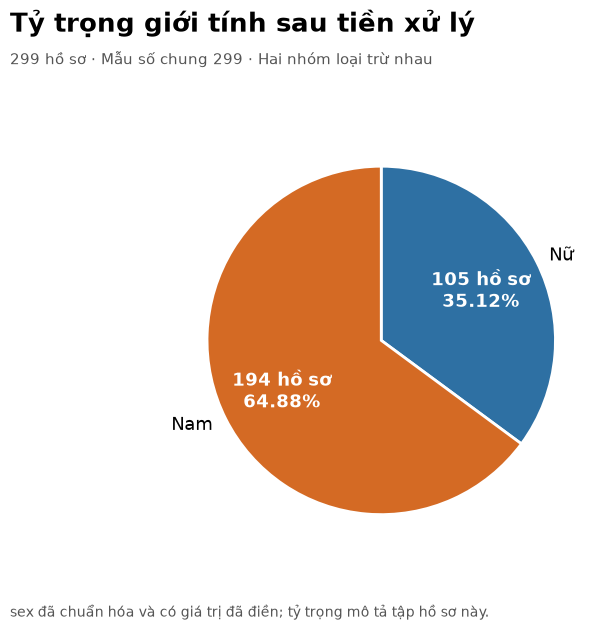

In [2]:
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":12})
fig, ax = plt.subplots(figsize=(9,6.5))
fig.subplots_adjust(top=0.80,bottom=0.13)
fig.text(0.10,0.94,"Tỷ trọng giới tính sau tiền xử lý",fontsize=19,weight="bold")
fig.text(0.10,0.89,"299 hồ sơ · Mẫu số chung 299 · Hai nhóm loại trừ nhau",fontsize=11,color="#555555")
lat, nhan, ty_le = ax.pie(bang["SoHoSo"],labels=bang["GioiTinh"],
    colors=["#2E70A3","#D46A24"],startangle=90,counterclock=False,
    autopct="%1.2f%%",pctdistance=0.64,labeldistance=1.08,
    wedgeprops={"edgecolor":"white","linewidth":2},
    textprops={"fontsize":13})
for text, n, pct in zip(ty_le,bang["SoHoSo"],bang["TyLePhanTram"]):
    text.set_text(f"{n} hồ sơ\n{pct:.2f}%")
    text.set_color("white")
    text.set_weight("bold")
assert len(lat)==2 and np.isclose(sum(w.theta2-w.theta1 for w in lat),360,atol=1e-4)
ax.set_aspect("equal")
fig.text(0.10,0.04,"sex đã chuẩn hóa và có giá trị đã điền; tỷ trọng mô tả tập hồ sơ này.",fontsize=10,color="#555555")
fig.savefig(thu_muc_kq / "15_pie_gioi_tinh.png",dpi=300,bbox_inches="tight",facecolor="white")
bang.to_csv(thu_muc_kq / "tong_hop_python.csv",index=False,encoding="utf-8-sig")
plt.show()


## Nhận xét

Nam có 194 hồ sơ (64,88%), nữ có 105 hồ sơ (35,12%). Nam nhiều hơn nữ 89 hồ sơ; tổng hai phần bằng 299 hồ sơ và tỷ lệ bằng 100% trước làm tròn.

Đây là cơ cấu giới tính của tập dữ liệu sau tiền xử lý, có cả giá trị sex đã điền ở N01. Không suy ra cơ cấu dân số hoặc kết luận nam có nguy cơ bệnh cao hơn. File after giữ nguyên; bảng tổng hợp và PNG được lưu riêng.
